0        5
1        5
2        5
3        4
4        3
        ..
20635    2
20636    2
20637    2
20638    2
20639    2
Name: income_cat, Length: 20640, dtype: category
Categories (5, int64): [1 < 2 < 3 < 4 < 5]


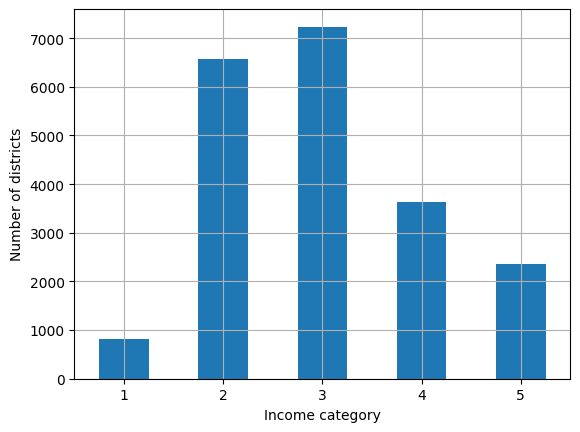

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

housing = pd.read_csv('/home/siyam/MyCodes/MachineLearning/Book/datasets/housing/housing.csv')

from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)


housing["income_cat"] = pd.cut(housing["median_income"],
bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
labels=[1, 2, 3, 4, 5])

print(housing["income_cat"])

housing["income_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")

from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=.2, random_state=42)

In [4]:
from sklearn.model_selection import StratifiedShuffleSplit
splitter = StratifiedShuffleSplit(n_splits=10,test_size=0.2,random_state=42)

# strat_splits = []

# for trainidx, testidx in splitter.split(housing, housing['income_cat']):
#     strat_trn = housing.iloc[trainidx]
#     strat_tst = housing.iloc[testidx]
#     strat_splits.append([strat_trn, strat_tst])

# for i, (train,test) in enumerate(strat_splits):
#     print(f"Split {i+1}:")
#     print("Train: ", train.shape)
#     print("Test : ", test.shape)
#     print()

strat_train_set, strat_test_set = train_test_split(housing, test_size=0.2, 
                                                   stratify=housing['income_cat'], 
                                                   random_state=42)

print(strat_test_set)

for x in (strat_train_set, strat_test_set):
    x.drop('income_cat', axis=1, inplace=True)

print(strat_test_set)


       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
3905     -121.95     37.11                21.0       2387.0           357.0   
16821    -118.01     33.89                36.0       1589.0           265.0   
2900     -118.18     33.74                30.0       5915.0          1750.0   
7193     -122.48     37.74                52.0       2166.0           423.0   
13928    -122.39     37.78                 5.0       1405.0           515.0   
...          ...       ...                 ...          ...             ...   
12369    -124.16     40.79                46.0       3042.0           597.0   
8707     -119.01     35.39                29.0       1820.0           459.0   
16634    -123.01     38.67                33.0        914.0           147.0   
9779     -122.03     37.60                24.0       2077.0           383.0   
3455     -117.12     32.74                52.0       1969.0           389.0   

       population  households  median_income  media